In [27]:

from os import listdir
from os.path import isfile, join


import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [31]:
path = '/home/barachiel/Documents/LupiNer/Arsene_Lupi-NER/output/'
all_paths = [file for file in listdir(path) if isfile(join(path,file))]
all_paths

['813_(1910,_Lafitte)_norm_fr_core_news_lg.csv',
 '813_(1910,_Lafitte)_norm_fr_core_news_md.csv',
 '813_(1910,_Lafitte)_norm_fr_core_news_sm.csv',
 '813_(1910,_Lafitte)_norm_fr_dep_news_trf.csv',
 'Arsène_Lupin_(pièce_de_théâtre)_norm_fr_core_news_lg.csv',
 'Arsène_Lupin_(pièce_de_théâtre)_norm_fr_core_news_md.csv',
 'Arsène_Lupin_(pièce_de_théâtre)_norm_fr_core_news_sm.csv',
 'Arsène_Lupin_(pièce_de_théâtre)_norm_fr_dep_news_trf.csv',
 'Arsène_Lupin_contre_Herlock_Sholmès_(1908)_norm_fr_core_news_lg.csv',
 'Arsène_Lupin_contre_Herlock_Sholmès_(1908)_norm_fr_core_news_md.csv',
 'Arsène_Lupin_contre_Herlock_Sholmès_(1908)_norm_fr_core_news_sm.csv',
 'Arsène_Lupin_contre_Herlock_Sholmès_(1908)_norm_fr_dep_news_trf.csv',
 'Arsène_Lupin_contre_Herlock_Sholmès_(1914)_norm_fr_core_news_lg.csv',
 'Arsène_Lupin_contre_Herlock_Sholmès_(1914)_norm_fr_core_news_md.csv',
 'Arsène_Lupin_contre_Herlock_Sholmès_(1914)_norm_fr_core_news_sm.csv',
 'Arsène_Lupin_contre_Herlock_Sholmès_(1914)_norm_fr_dep

In [72]:
df = pd.DataFrame(columns=['entity', 'label', 'occurence', 'model'])
for file in all_paths[:3]:
    data = pd.read_csv(f"{path}/{file}")
    model = file.split('.')[0]
    data['model'] = model.split('norm_')[1]
    df = pd.concat([df, data], ignore_index=True)
df

,entity,label,occurence,model
0,Altenheim,total,114,fr_core_news_lg
1,Altenheim,LOC,114,fr_core_news_lg
2,Doudeville,total,58,fr_core_news_lg
3,Doudeville,LOC,58,fr_core_news_lg
4,Paris,total,35,fr_core_news_lg
...,...,...,...,...
1829,grand-duché de Veldenz,LOC,1,fr_core_news_sm
1830,Abasourdi,total,1,fr_core_news_sm
1831,Abasourdi,LOC,1,fr_core_news_sm
1832,caserne de la,total,1,fr_core_news_sm


In [73]:
df.describe()

,entity,label,occurence,model
count,1834,1834,1834,1834
unique,476,2,34,3
top,grand-duché de Veldenz,total,1,fr_core_news_sm
freq,6,917,1120,750


In [74]:
df = df.sort_values('entity')
df = df[df['label'] != 'total']
df = df[df['occurence'] > 5]
df

,entity,label,occurence,model
563,Allemagne,LOC,13,fr_core_news_md
1119,Allemagne,LOC,12,fr_core_news_sm
31,Allemagne,LOC,12,fr_core_news_lg
25,Allemand,LOC,12,fr_core_news_lg
1127,Allemand,LOC,10,fr_core_news_sm
...,...,...,...,...
1139,sauta,LOC,6,fr_core_news_sm
15,vieux Steinweg,LOC,18,fr_core_news_lg
547,villa Dupont,LOC,20,fr_core_news_md
1105,villa Dupont,LOC,18,fr_core_news_sm


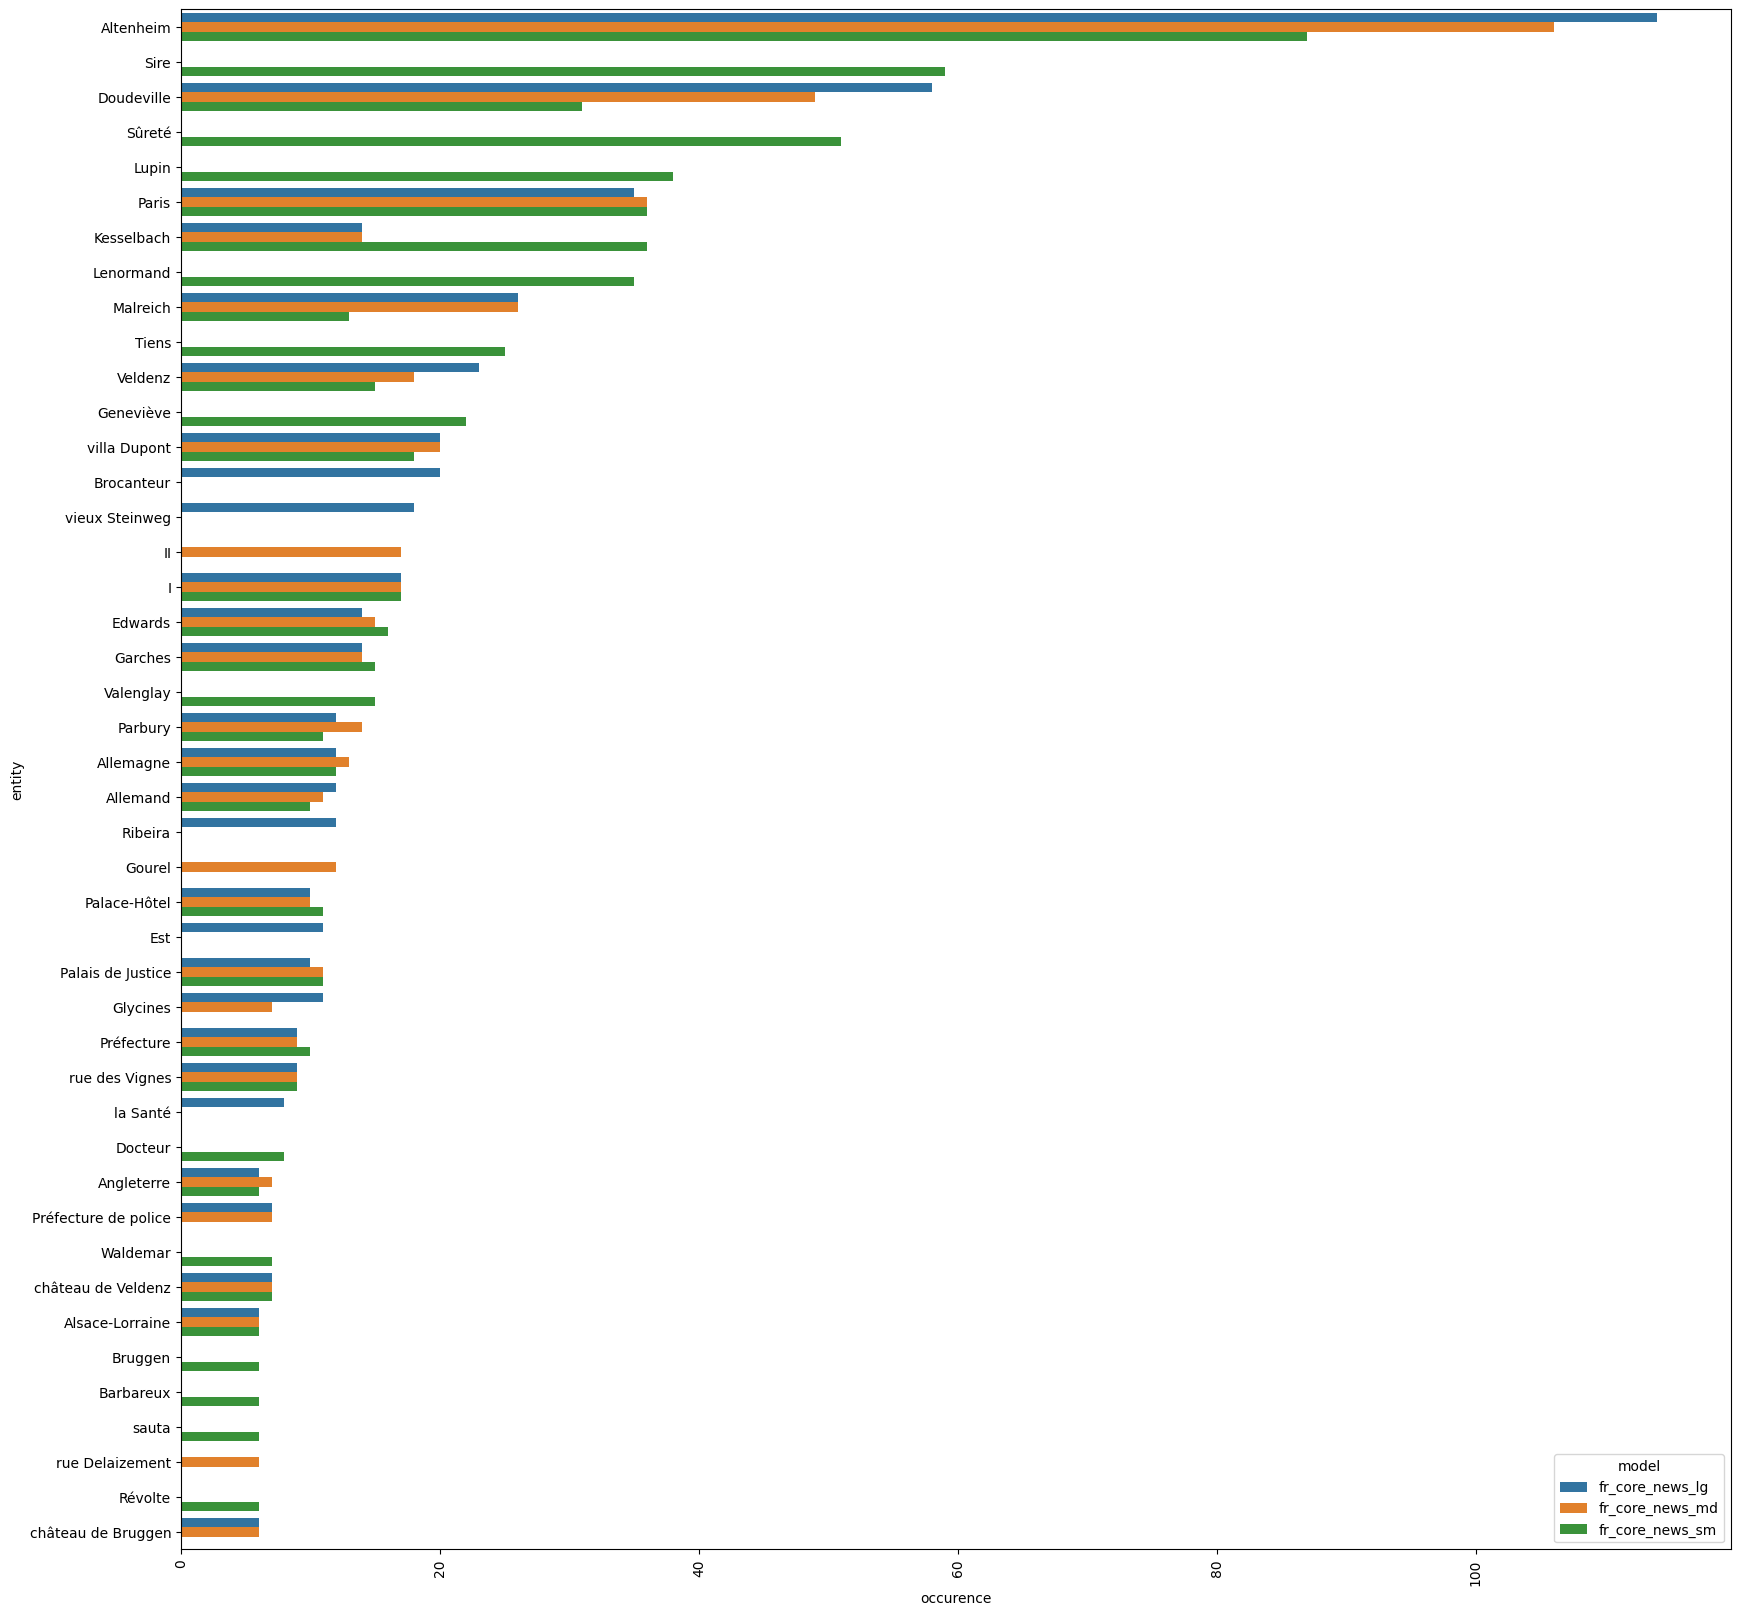

In [75]:
plt.figure(figsize=(20, 20))
sns.barplot(df.sort_values('occurence', ascending=False), 
            y='entity', 
            x='occurence',
            hue='model')
plt.xticks(rotation=90)
plt.show()